In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats

# Dataset Definition
X = np.array([0.5, 2.3, 2.9])
y = np.array([1.4, 1.9, 3.2])

print("Height (X):", X)
print("Weight (y):", y)
print("Number of observations:", len(X))


Height (X): [0.5 2.3 2.9]
Weight (y): [1.4 1.9 3.2]
Number of observations: 3


In [2]:

# ============================================================
# TASK 1: Ordinary Least Squares (OLS) Implementation
# ============================================================

def ols_linear_regression(X, y):
    """
    Compute linear regression parameters analytically using OLS.

    Parameters:
        X (np.ndarray): Input feature vector (Height)
        y (np.ndarray): Target vector (Weight)

    Returns:
        m (float): Optimal slope
        c (float): Optimal intercept
    """

    # TODO 1.1: Compute mean of X and mean of y
    x_mean = np.mean(X)
    y_mean = np.mean(y)

    # TODO 1.2: Compute numerator and denominator for slope m
    numerator = np.sum((X - x_mean) * (y - y_mean))
    denominator = np.sum((X - x_mean) ** 2)
    m = numerator / denominator

    # TODO 1.3: Compute intercept c
    c = y_mean - m * x_mean

    return m, c


# Test the OLS function
m_ols, c_ols = ols_linear_regression(X, y)

print("OLS slope (m):", round(m_ols, 4))
print("OLS intercept (c):", round(c_ols, 4))
print(f"OLS equation: y = {m_ols:.4f}x + {c_ols:.4f}")


OLS slope (m): 0.641
OLS intercept (c): 0.9487
OLS equation: y = 0.6410x + 0.9487


In [3]:

# ============================================================
# TASK 2: Batch Gradient Descent Implementation
# ============================================================

def gradient_descent(X, y, alpha=0.05, epochs=1000):
    """
    Optimize linear regression parameters using batch gradient descent.

    Parameters:
        X (np.ndarray): Input feature vector
        y (np.ndarray): Target vector
        alpha (float): Learning rate
        epochs (int): Total training iterations

    Returns:
        m (float): Learned slope
        c (float): Learned intercept
        loss_history (list): MSE loss recorded per epoch
    """

    m = 0.0
    c = 0.0
    n = len(X)
    loss_history = []

    for epoch in range(epochs):
        # TODO 2.1: Compute linear predictions
        y_pred = m * X + c

        # TODO 2.2: Compute Mean Squared Error and record the loss
        loss = np.mean((y_pred - y) ** 2)
        loss_history.append(loss)

        # TODO 2.3: Compute partial derivatives
        dm = (2 / n) * np.sum((y_pred - y) * X)
        dc = (2 / n) * np.sum(y_pred - y)

        # TODO 2.4: Update parameters using gradients
        m = m - alpha * dm
        c = c - alpha * dc

    return m, c, loss_history


# Test Gradient Descent
alpha = 0.05
epochs = 1500

m_gd, c_gd, losses = gradient_descent(
    X, y, alpha=alpha, epochs=epochs
)

print("Gradient Descent slope (m):", round(m_gd, 4))
print("Gradient Descent intercept (c):", round(c_gd, 4))
print(f"Gradient Descent equation: y = {m_gd:.4f}x + {c_gd:.4f}")
print("Initial MSE loss:", round(losses[0], 6))
print("Final MSE loss:", round(losses[-1], 6))


Gradient Descent slope (m): 0.641
Gradient Descent intercept (c): 0.9487
Gradient Descent equation: y = 0.6410x + 0.9487
Initial MSE loss: 5.27
Final MSE loss: 0.148205


In [4]:

# ============================================================
# TASK 3: Model Evaluation Metrics (R2, t-statistic, p-value)
# ============================================================

def compute_evaluation_metrics(X, y, y_pred, m):
    """
    Calculate R-squared and statistical significance
    (p-value) of the slope parameter.
    """

    n = len(X)
    df = n - 2

    # TODO 3.1: Calculate SS_res and SS_tot
    ss_res = np.sum((y - y_pred) ** 2)
    ss_tot = np.sum((y - np.mean(y)) ** 2)

    # TODO 3.2: Calculate R-squared
    r2 = 1 - (ss_res / ss_tot)

    # TODO 3.3: Calculate standard error of the slope
    residual_variance = ss_res / df
    se_m = np.sqrt(
        residual_variance / np.sum((X - np.mean(X)) ** 2)
    )

    # TODO 3.4: Compute t-statistic
    t_stat = m / se_m

    # TODO 3.5: Compute two-tailed p-value
    p_val = 2 * stats.t.sf(abs(t_stat), df)

    return r2, t_stat, p_val


# Evaluate OLS model
y_pred_ols = m_ols * X + c_ols
r2_ols, t_ols, p_ols = compute_evaluation_metrics(
    X, y, y_pred_ols, m_ols
)

# Evaluate Gradient Descent model
y_pred_gd = m_gd * X + c_gd
r2_gd, t_gd, p_gd = compute_evaluation_metrics(
    X, y, y_pred_gd, m_gd
)

print("=============== OLS RESULTS ===============")
print(f"R-squared : {r2_ols:.4f}")
print(f"t-statistic: {t_ols:.4f}")
print(f"p-value    : {p_ols:.4f}")

print("\n========== GRADIENT DESCENT RESULTS ==========")
print(f"R-squared : {r2_gd:.4f}")
print(f"t-statistic: {t_gd:.4f}")
print(f"p-value    : {p_gd:.4f}")


=============== OLS RESULTS ===============
R-squared : 0.7425
t-statistic: 1.6981
p-value    : 0.3388

========== GRADIENT DESCENT RESULTS ==========
R-squared : 0.7425
t-statistic: 1.6981
p-value    : 0.3388


===================== OLS RESULTS =====================
Equation   : y = 0.6410x + 0.9487
R-squared  : 0.7425
t-statistic: 1.6981
p-value    : 0.3388

=============== GRADIENT DESCENT RESULTS ===============
Equation   : y = 0.6410x + 0.9487
R-squared  : 0.7425
t-statistic: 1.6981
p-value    : 0.3388



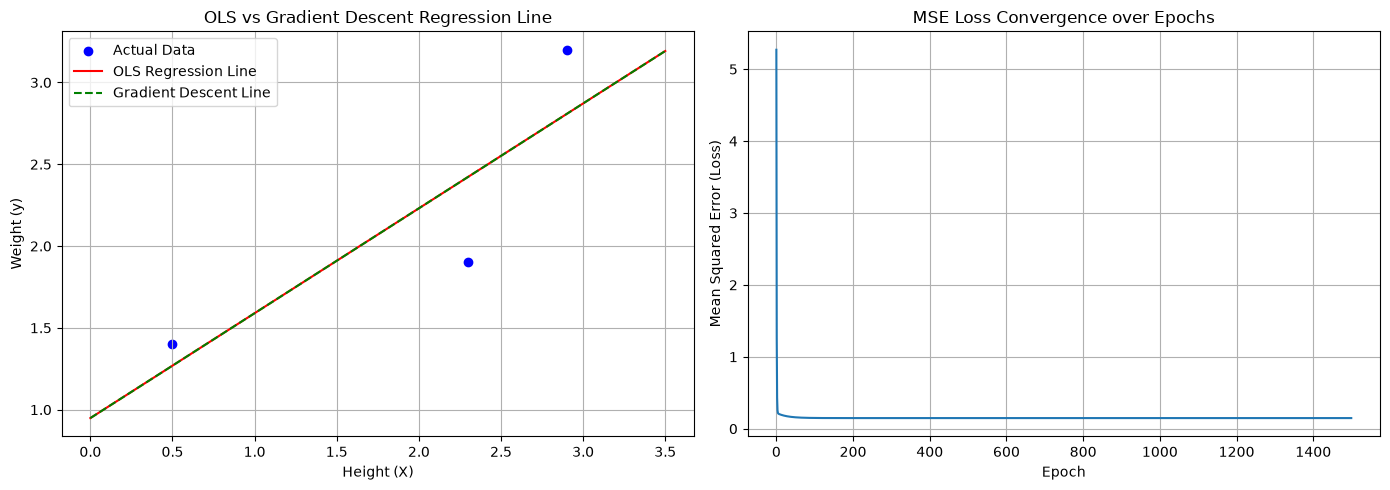

In [5]:

# ============================================================
# TASK 4: Model Execution & Evaluation Comparison
# TASK 5: Plotting & Visualization
# ============================================================

# Print OLS results
print("===================== OLS RESULTS =====================")
print(f"Equation   : y = {m_ols:.4f}x + {c_ols:.4f}")
print(f"R-squared  : {r2_ols:.4f}")
print(f"t-statistic: {t_ols:.4f}")
print(f"p-value    : {p_ols:.4f}\n")

# Print Gradient Descent results
print("=============== GRADIENT DESCENT RESULTS ===============")
print(f"Equation   : y = {m_gd:.4f}x + {c_gd:.4f}")
print(f"R-squared  : {r2_gd:.4f}")
print(f"t-statistic: {t_gd:.4f}")
print(f"p-value    : {p_gd:.4f}\n")

# Create a 2-panel plot
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Subplot 1: Regression Fit Comparison
axes[0].scatter(X, y, color="blue", label="Actual Data")

# Generate values for fitted regression lines
x_vals = np.linspace(0, 3.5, 100)

axes[0].plot(
    x_vals, m_ols * x_vals + c_ols,
    color="red", label="OLS Regression Line"
)

axes[0].plot(
    x_vals, m_gd * x_vals + c_gd,
    color="green", linestyle="--",
    label="Gradient Descent Line"
)

axes[0].set_title("OLS vs Gradient Descent Regression Line")
axes[0].set_xlabel("Height (X)")
axes[0].set_ylabel("Weight (y)")
axes[0].legend()
axes[0].grid(True)

# Subplot 2: Loss Convergence Curve
axes[1].plot(range(len(losses)), losses)
axes[1].set_title("MSE Loss Convergence over Epochs")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Mean Squared Error (Loss)")
axes[1].grid(True)

plt.tight_layout()
plt.show()



# 6. Lab Report & Viva Questions

1. Analytical vs. Iterative Comparison

The values of slope (m), intercept (c), and R-squared obtained using both OLS and Gradient Descent are almost the same. OLS calculates the best-fit line directly using mathematical formulas, whereas Gradient Descent finds the best values by updating the parameters over multiple iterations. Small differences may occur if Gradient Descent has not fully converged.

2. Interpreting R-squared vs. p-value for Small Sample Sizes (n = 3)

A high R-squared value means that the regression line explains a large part of the variation in the data. However, it does not always mean that the slope is statistically significant. In this experiment, there are only three observations, so the degrees of freedom are just one. Because of this small sample size, it is difficult to draw a reliable conclusion about the relationship between Height and Weight, even when R-squared is high.

3. Hypothesis Testing

The null hypothesis (H0) states that the slope is zero (m = 0), which means there is no linear relationship between Height and Weight. The alternative hypothesis (H1) states that the slope is not zero (m != 0), meaning a linear relationship may exist. The t-statistic and p-value help us decide whether the slope is statistically significant.

4. Learning Rate Sensitivity

If the learning rate is increased to alpha = 1.0, the parameter updates may become too large, causing the algorithm to overshoot the minimum or even diverge. On the other hand, if the learning rate is reduced to alpha = 0.0001, the updates become very small and the algorithm takes much longer to converge.

5. Computational Scalability

OLS may require the inversion of the matrix (X^T X), which becomes computationally expensive when the dataset has a large number of features. Gradient Descent avoids this direct matrix inversion and updates the parameters step by step. Therefore, it is often more practical for large datasets, especially when using stochastic or mini-batch Gradient Descent.
